# Heart Disease Prediction Using Machine Learning

## Project Overview

This project explores supervised machine learning techniques to classify heart disease status using clinical features from the UCI Heart Disease dataset.

### Objectives
- Understand and explore clinical tabular data.
- Perform data cleaning and exploratory data analysis (EDA).
- Train and compare multiple classification models.
- Evaluate models using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.
- Document the workflow and results for a reproducible GitHub portfolio project.

### Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Google Colab, and GitHub.

### Important Note
This project is for educational purposes only. Its predictions are not medical diagnoses and must not be used to make healthcare decisions.



In [1]:
# Import essential libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Dataset Loading and Understanding

In this section, we load the UCI Heart Disease dataset, inspect its structure, identify missing values, and understand the target variable before performing exploratory data analysis.

In [2]:
# Load the UCI Heart Disease dataset

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# Check dataset information
print("Dataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Missing values per column:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Statistical summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [4]:
# Convert the original target into a binary target

df["target"] = (df["target"] > 0).astype(int)

print("Binary target distribution:")
print(df["target"].value_counts())

print("\nTarget proportions:")
print(df["target"].value_counts(normalize=True).round(3))

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64

Target proportions:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset's structure, feature distributions, class balance, and relationships between variables. These insights guide preprocessing and model selection.

In [5]:
# Check missing values and duplicate records

print("Missing values per column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget class counts:")
print(df["target"].value_counts())

Missing values per column:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Total missing values: 6
Duplicate rows: 0

Target class counts:
target
0    164
1    139
Name: count, dtype: int64


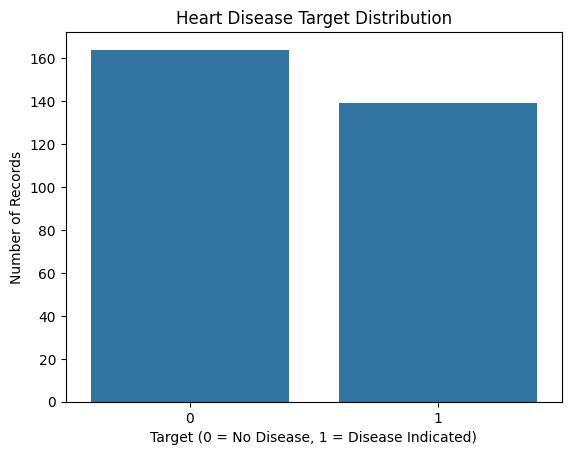

In [6]:
# Visualize the number of records in each target class

sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease Indicated)")
plt.ylabel("Number of Records")
plt.show()

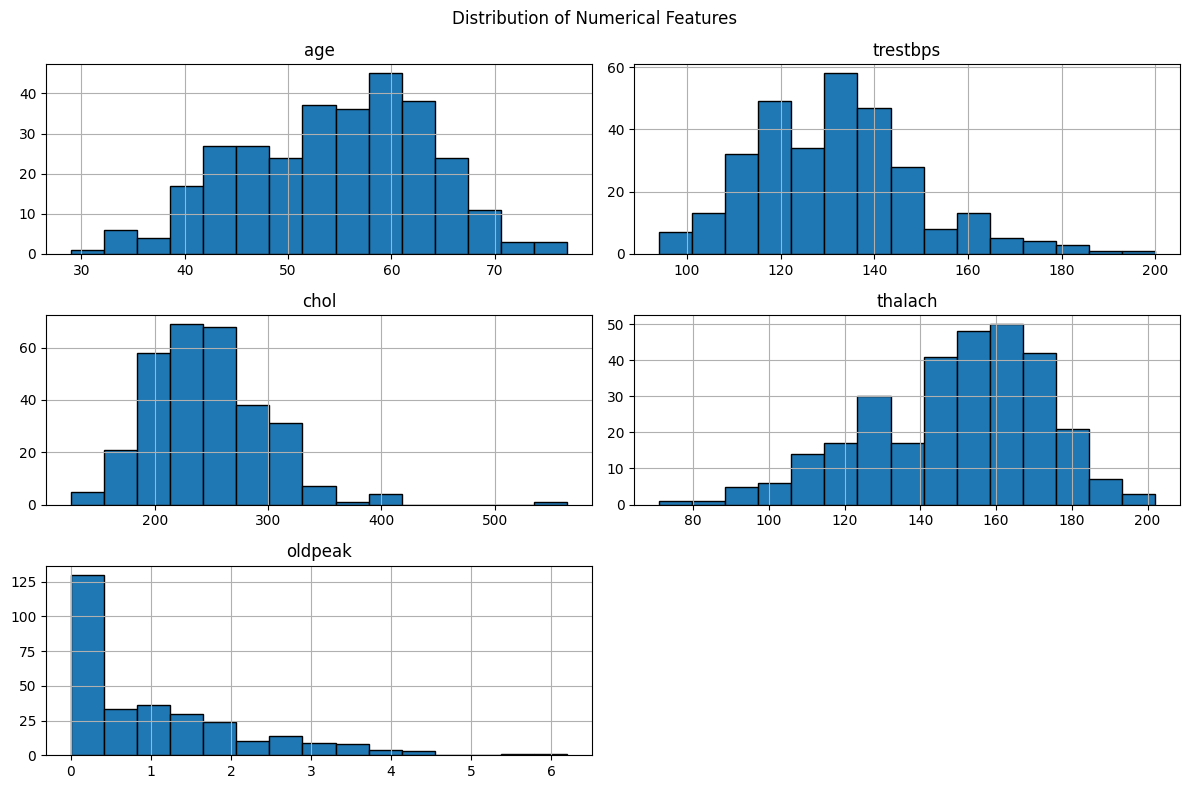

In [7]:
# Distribution of selected numerical features

numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

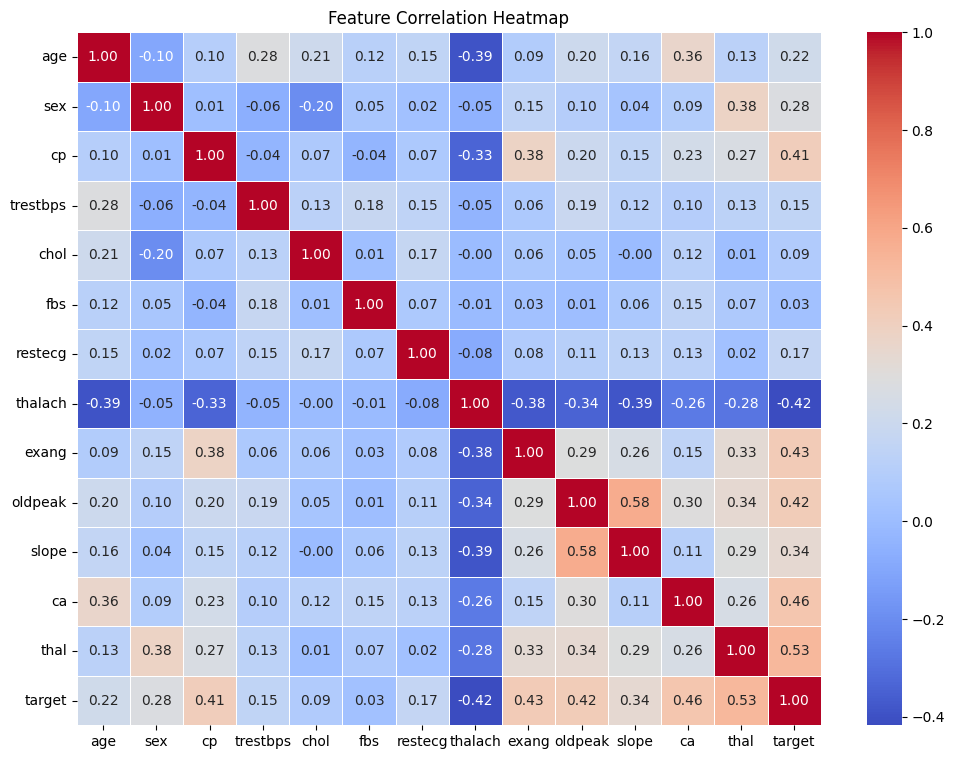

In [8]:
# Correlation heatmap

plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

## 4. Data Preprocessing

Data preprocessing prepares the dataset for machine learning. In this stage, we separate input features from the target, split the data into training and testing sets, and define preprocessing steps for missing values and numerical scaling.

To avoid data leakage, preprocessing will be fitted only on the training data through a Scikit-learn Pipeline.

In [9]:
# Separate input features and target variable

X = df.drop(columns=["target"])
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (303, 13)
Target shape: (303,)

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [10]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 242
Testing samples: 61

Training class distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing class distribution:
target
0    33
1    28
Name: count, dtype: int64


In [11]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 242
Testing samples: 61

Training class distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing class distribution:
target
0    33
1    28
Name: count, dtype: int64


In [12]:
# Identify numerical and categorical columns

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Build preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [14]:
# Confirm there are no missing target labels

print("Missing target values:", y.isnull().sum())
print("Missing values in raw training features:",
      X_train.isnull().sum().sum())
print("Missing values in raw testing features:",
      X_test.isnull().sum().sum())

Missing target values: 0
Missing values in raw training features: 2
Missing values in raw testing features: 4


## 5. Model Training

In this stage, we train and compare three supervised machine learning classification algorithms:

1. **Logistic Regression:** A linear classification model that provides a useful baseline.
2. **Decision Tree:** A tree-based model that learns decision rules from feature values.
3. **Random Forest:** An ensemble model that combines multiple decision trees.

Each model uses the same preprocessing pipeline and training split to ensure a fair comparison. The test set remains separate until final evaluation.

In [16]:
# Define candidate models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )
}

# Train each model using the preprocessing pipeline

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

print("\nAll models have been trained.")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All models have been trained.


In [17]:
# Evaluate models on the held-out test set

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.885,0.839,0.929,0.881,0.966
1,Random Forest,0.869,0.833,0.893,0.862,0.945
2,Decision Tree,0.738,0.700,0.750,0.724,0.745


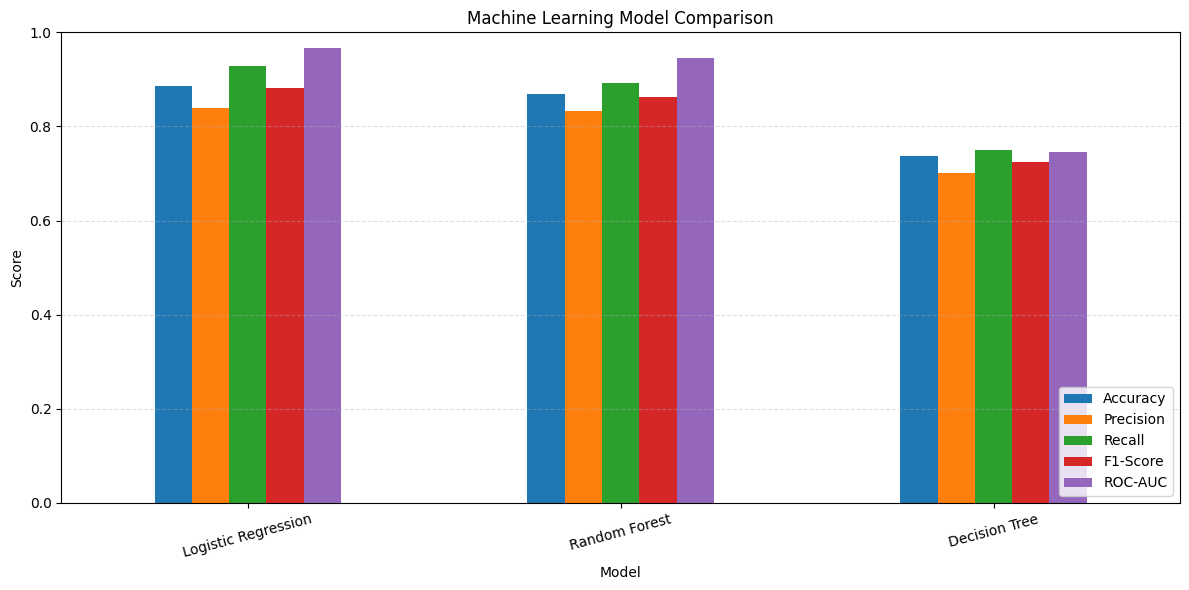

In [18]:
# Compare model scores visually

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=15
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 6. Detailed Model Evaluation

We evaluate the selected Logistic Regression model using a confusion matrix and classification report. These provide class-wise precision, recall, F1-score, and counts of correct and incorrect predictions on the held-out test set.

Selected model: Logistic Regression

Classification Report:
                      precision    recall  f1-score   support

No Disease Indicated      0.933     0.848     0.889        33
   Disease Indicated      0.839     0.929     0.881        28

            accuracy                          0.885        61
           macro avg      0.886     0.889     0.885        61
        weighted avg      0.890     0.885     0.885        61



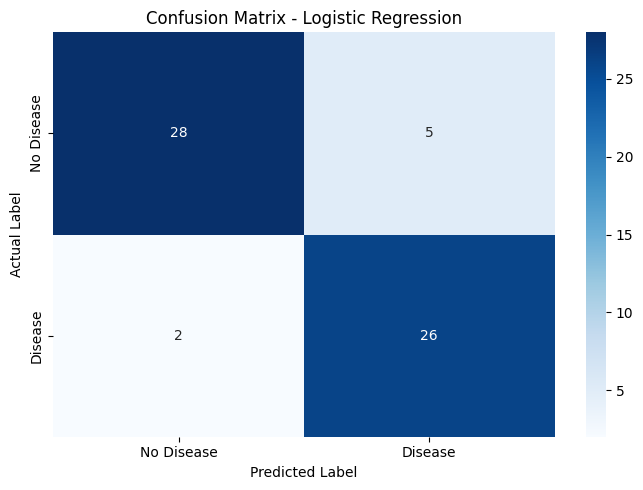

In [19]:
# Select the best candidate based on test F1-score
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

# Generate predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Disease Indicated", "Disease Indicated"],
    digits=3,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [20]:
# Save model comparison results

results_df.to_csv("model_comparison.csv", index=False)

print("Saved model_comparison.csv")

Saved model_comparison.csv


## 7. Model Export

The selected Logistic Regression pipeline is exported using Joblib. The saved pipeline includes preprocessing steps such as missing-value imputation, feature scaling, categorical encoding, and the trained classifier.

This supports reproducible inference without manually repeating the preprocessing steps.

In [21]:
import joblib

# Save the complete pipeline
joblib.dump(best_model, "heart_disease_model.joblib")

print("Model saved successfully!")

Model saved successfully!


## 8. Conclusion

Three machine learning models were evaluated using the same training and testing split. Logistic Regression achieved the strongest reported performance among the tested models based on accuracy, F1-score, and ROC-AUC.

These results are educational and do not establish clinical validity. The model must not be used for medical diagnosis or healthcare decisions.